In [ ]:
!pip install -q google-genai

In [ ]:
!pip -q install -U ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 25.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 11.1 MB/s eta 0:00:00


In [ ]:
!pip install tqdm

In [ ]:
from google.colab import userdata
from google import genai

GOOGLE_API_KEY = userdata.get('GOOGLE_API_KEY')
client = genai.Client(api_key=GOOGLE_API_KEY)

In [ ]:
from google.colab import files
from IPython.display import display, Video, Image
from google.genai import types

In [ ]:
from ultralytics import YOLO
from PIL import Image as PILImage
from tqdm.auto import tqdm

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [ ]:
import cv2
import os
import json
import math
import textwrap
import getpass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

In [ ]:
# Configuración del proyecto
OUTPUT_DIR = "/content/resultados_carretera"
os.makedirs(OUTPUT_DIR, exist_ok=True)

VIDEO_OUT = f"{OUTPUT_DIR}/carretera_tiktok.mp4"
CHART_TIME = f"{OUTPUT_DIR}/detecciones_tiempo.png"
CHART_CLASS = f"{OUTPUT_DIR}/vehiculos_clase.png"
REPORT_OUT = f"{OUTPUT_DIR}/analisis_gemini.txt"
CSV_OUT = f"{OUTPUT_DIR}/estadisticas.csv"

# Subir el video de carretera
uploaded = files.upload()
VIDEO_IN = next(iter(uploaded.keys()))

cap = cv2.VideoCapture(VIDEO_IN)

if not cap.isOpened():
    raise ValueError("No se pudo abrir el video.")

fps = cap.get(cv2.CAP_PROP_FPS)
fps = fps if fps and fps > 0 else 25

TOTAL_FRAMES = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
WIDTH = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
HEIGHT = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
DURATION = TOTAL_FRAMES / fps

print(f"Video: {VIDEO_IN}")
print(f"Resolución: {WIDTH}x{HEIGHT}")
print(f"FPS: {fps:.2f}")
print(f"Duración: {DURATION:.1f} segundos")

cap.release()


Saving 854671-hd_1920_1080_25fps.mp4 to 854671-hd_1920_1080_25fps.mp4
Video: 854671-hd_1920_1080_25fps.mp4
Resolución: 1920x1080
FPS: 25.00
Duración: 60.0 segundos


In [ ]:

GEMINI_MODEL = "gemini-3.5-flash"

# Comprobar acceso al modelo antes de procesar el video
respuesta = client.models.generate_content(
    model=GEMINI_MODEL,
    contents="Responde únicamente: Sistema de análisis de carretera listo."
)

print(respuesta.text)


Sistema de análisis de carretera listo.


In [ ]:
model = YOLO("yolo26n-seg.pt")

# Clases COCO que nos interesan
VEHICLE_CLASSES = {
    2: "Automovil",
    3: "Motocicleta",
    5: "Autobus",
    7: "Camion"
}

CONFIDENCE = 0.25
IMGSZ = 640

# Ajustes para el video final
OUT_W = 720
OUT_H = 1280
VIDEO_H = 800
PANEL_H = OUT_H - VIDEO_H

# Limitar el video para un primer experimento
MAX_SECONDS = 45
MAX_FRAMES = min(TOTAL_FRAMES, int(MAX_SECONDS * fps))

# Analizar con Gemini hasta 4 fotogramas distribuidos
GEMINI_SAMPLES = 4

print("Modelo YOLO listo.")
print("Clases:", list(VEHICLE_CLASSES.values()))
print("Fotogramas a procesar:", MAX_FRAMES)


Modelo YOLO listo.
Clases: ['Automovil', 'Motocicleta', 'Autobus', 'Camion']
Fotogramas a procesar: 1125


In [ ]:

def fit_frame(frame, target_w, target_h):
    """Ajusta el fotograma sin deformar la imagen."""
    h, w = frame.shape[:2]
    scale = min(target_w / w, target_h / h)

    nw = max(1, int(w * scale))
    nh = max(1, int(h * scale))

    resized = cv2.resize(frame, (nw, nh))
    canvas = np.zeros((target_h, target_w, 3), dtype=np.uint8)

    x = (target_w - nw) // 2
    y = (target_h - nh) // 2
    canvas[y:y+nh, x:x+nw] = resized

    return canvas


def draw_panel(frame, elapsed, total, counts):
    """Panel inferior de estilo tecnológico para TikTok."""
    panel = np.zeros((PANEL_H, OUT_W, 3), dtype=np.uint8)
    panel[:] = (22, 25, 35)

    cv2.putText(
        panel, "AI HIGHWAY ANALYTICS",
        (24, 42), cv2.FONT_HERSHEY_DUPLEX,
        0.85, (255, 255, 255), 2, cv2.LINE_AA
    )

    cv2.putText(
        panel, f"TIME {elapsed:05.1f}s",
        (24, 82), cv2.FONT_HERSHEY_SIMPLEX,
        0.65, (170, 220, 255), 2, cv2.LINE_AA
    )

    cv2.putText(
        panel, f"VEHICLES IN FRAME: {total}",
        (24, 132), cv2.FONT_HERSHEY_DUPLEX,
        0.78, (80, 255, 180), 2, cv2.LINE_AA
    )

    y = 184
    for cls_name in ["Automovil", "Motocicleta",
                     "Autobus", "Camion"]:
        value = counts.get(cls_name, 0)
        cv2.putText(
            panel, f"{cls_name}: {value}",
            (28, y), cv2.FONT_HERSHEY_SIMPLEX,
            0.65, (235, 235, 235), 1, cv2.LINE_AA
        )
        y += 39

    cv2.putText(
        panel, "YOLO SEGMENTATION + GEMINI AI",
        (24, PANEL_H - 26),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.48, (180, 190, 210), 1, cv2.LINE_AA
    )

    frame[VIDEO_H:OUT_H, :] = panel
    return frame


cap = cv2.VideoCapture(VIDEO_IN)

fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(
    VIDEO_OUT, fourcc, fps, (OUT_W, OUT_H)
)

if not writer.isOpened():
    cap.release()
    raise RuntimeError("No se pudo crear el video de salida.")

# Fotogramas que se enviarán a Gemini
sample_indices = set(
    np.linspace(
        0, max(0, MAX_FRAMES - 1),
        num=min(GEMINI_SAMPLES, MAX_FRAMES),
        dtype=int
    ).tolist()
)

gemini_frames = []
frame_records = []
class_totals = Counter()

try:
    for i in tqdm(range(MAX_FRAMES), desc="YOLO segmentando"):
        ok, frame = cap.read()
        if not ok:
            break

        # Tracking conserva IDs entre fotogramas cuando es posible
        results = model.track(
            frame,
            persist=True,
            tracker="bytetrack.yaml",
            conf=CONFIDENCE,
            imgsz=IMGSZ,
            classes=list(VEHICLE_CLASSES.keys()),
            verbose=False
        )

        result = results[0]

        # plot() incluye las máscaras si el modelo es de segmentación
        annotated = result.plot()

        counts = Counter()
        total = 0

        if result.boxes is not None and len(result.boxes) > 0:
            class_ids = result.boxes.cls.cpu().numpy().astype(int)

            for class_id in class_ids:
                name = VEHICLE_CLASSES.get(class_id)
                if name:
                    counts[name] += 1
                    class_totals[name] += 1
                    total += 1

        elapsed = i / fps

        frame_records.append({
            "frame": i,
            "tiempo_segundos": elapsed,
            "vehiculos_detectados": total,
            **{
                name: counts.get(name, 0)
                for name in VEHICLE_CLASSES.values()
            }
        })

        # Guardar fotogramas para análisis contextual con Gemini
        if i in sample_indices:
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            gemini_frames.append((elapsed, PILImage.fromarray(rgb)))

        # Composición vertical 9:16
        top = fit_frame(annotated, OUT_W, VIDEO_H)
        canvas = np.zeros((OUT_H, OUT_W, 3), dtype=np.uint8)
        canvas[:VIDEO_H] = top
        canvas = draw_panel(canvas, elapsed, total, counts)

        writer.write(canvas)

finally:
    cap.release()
    writer.release()

print("Video generado:", VIDEO_OUT)
print("Fotogramas procesados:", len(frame_records))
print("Muestras para Gemini:", len(gemini_frames))


YOLO segmentando:   0%|          | 0/1125 [00:00<?, ?it/s]

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 273ms
Prepared 1 package in 88ms
Installed 1 package in 1ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Video generado: /content/resultados_carretera/carretera_tiktok.mp4
Fotogramas procesados: 1125
Muestras para Gemini: 4


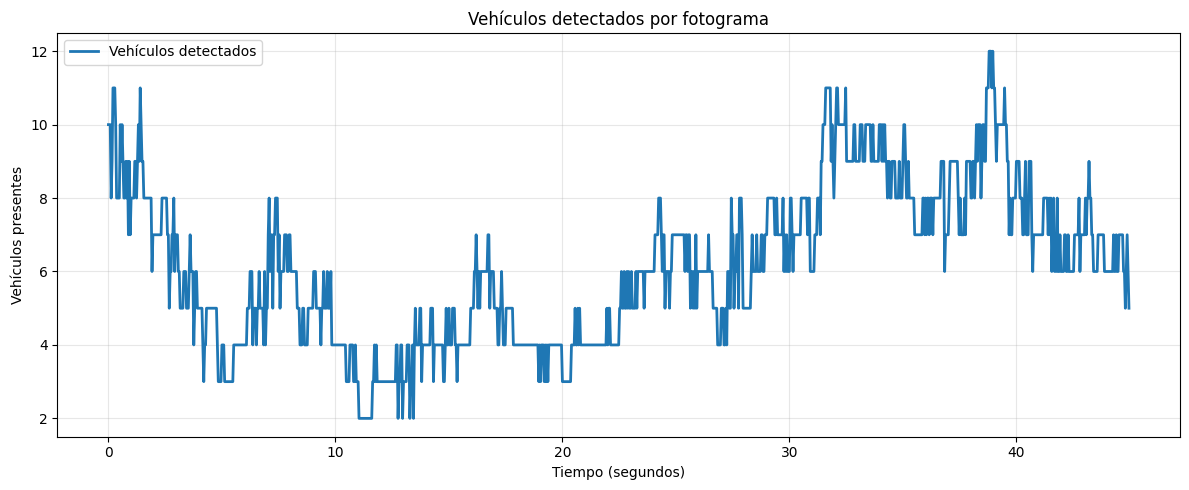

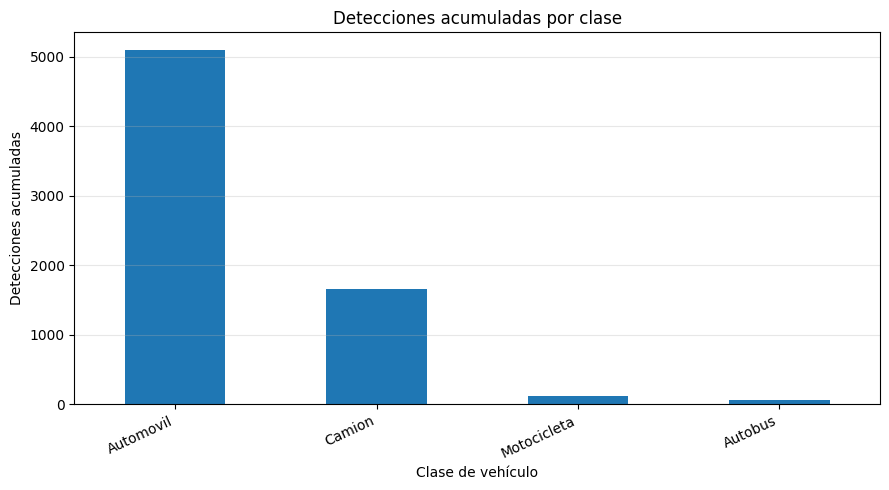

Promedio de vehículos por fotograma: 6.15
Máximo en un fotograma: 12
CSV guardado: /content/resultados_carretera/estadisticas.csv


In [ ]:

df = pd.DataFrame(frame_records)

if df.empty:
    raise ValueError("No se procesaron fotogramas.")

df.to_csv(CSV_OUT, index=False, encoding="utf-8-sig")

# Gráfica 1: evolución de las detecciones
plt.figure(figsize=(12, 5))
plt.plot(
    df["tiempo_segundos"],
    df["vehiculos_detectados"],
    linewidth=2,
    label="Vehículos detectados"
)
plt.title("Vehículos detectados por fotograma")
plt.xlabel("Tiempo (segundos)")
plt.ylabel("Vehículos presentes")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(CHART_TIME, dpi=180)
plt.show()

# Gráfica 2: distribución de las clases
class_columns = list(VEHICLE_CLASSES.values())
totals = df[class_columns].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
totals.plot(kind="bar")
plt.title("Detecciones acumuladas por clase")
plt.xlabel("Clase de vehículo")
plt.ylabel("Detecciones acumuladas")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(CHART_CLASS, dpi=180)
plt.show()

print("Promedio de vehículos por fotograma:",
      round(df["vehiculos_detectados"].mean(), 2))
print("Máximo en un fotograma:",
      int(df["vehiculos_detectados"].max()))
print("CSV guardado:", CSV_OUT)


In [ ]:

prompt = """
Actúa como analista de visión artificial y divulgador científico.

Analiza las imágenes seleccionadas de una escena de carretera.

Redacta en español:
1. Descripción general de la escena.
2. Tipos de vehículos visibles.
3. Distribución aparente del tráfico.
4. Comportamientos observables, únicamente si son visibles.
5. Condiciones visibles de iluminación y carretera.
6. Qué puede medir YOLO y qué no puede concluirse con estas imágenes.
7. Una narración dinámica de 60 a 80 palabras para un TikTok
   sobre inteligencia artificial y visión por computadora.

No inventes velocidades, distancias, matrículas, causas de accidentes,
identidades, ni condiciones meteorológicas que no sean evidentes.
No afirmes que un vehículo está en movimiento basándote en una sola
imagen. Distingue observaciones de hipótesis.
"""

contents = [prompt]

for t, pil_image in gemini_frames:
    contents.append(f"Fotograma del segundo {t:.1f}:")
    contents.append(pil_image)

response = client.models.generate_content(
    model=GEMINI_MODEL,
    contents=contents
)

scene_report = response.text or "Gemini no devolvió una descripción."

with open(REPORT_OUT, "w", encoding="utf-8") as f:
    f.write(scene_report)

print(scene_report)


A continuación, presento el análisis técnico de las imágenes desde la perspectiva de la visión artificial y la divulgación científica.

---

### 1. Descripción general de la escena
La escena muestra una sección de una carretera de múltiples carriles con tráfico fluyendo en un solo sentido, dirigiéndose de frente hacia el punto de observación de la cámara. En el margen izquierdo de la calzada se observa un guardarraíl metálico y un poste con un dispositivo de control o señalización apagado (con la inscripción "9448A"). En el margen derecho se aprecia una franja de césped, vegetación arbórea deshojada y un poste de auxilio SOS de color naranja.

### 2. Tipos de vehículos visibles
A lo largo de los diferentes fotogramas, se identifican principalmente turismos de tipología variada:
*   **Sedanes y compactos (Hatchbacks):** Modelos de marcas como Audi, BMW, Mercedes-Benz, Citroën, entre otros.
*   **Vehículos utilitarios deportivos (SUV):** Como un Nissan rojo (segundo 0.0) y un Toyota RAV4

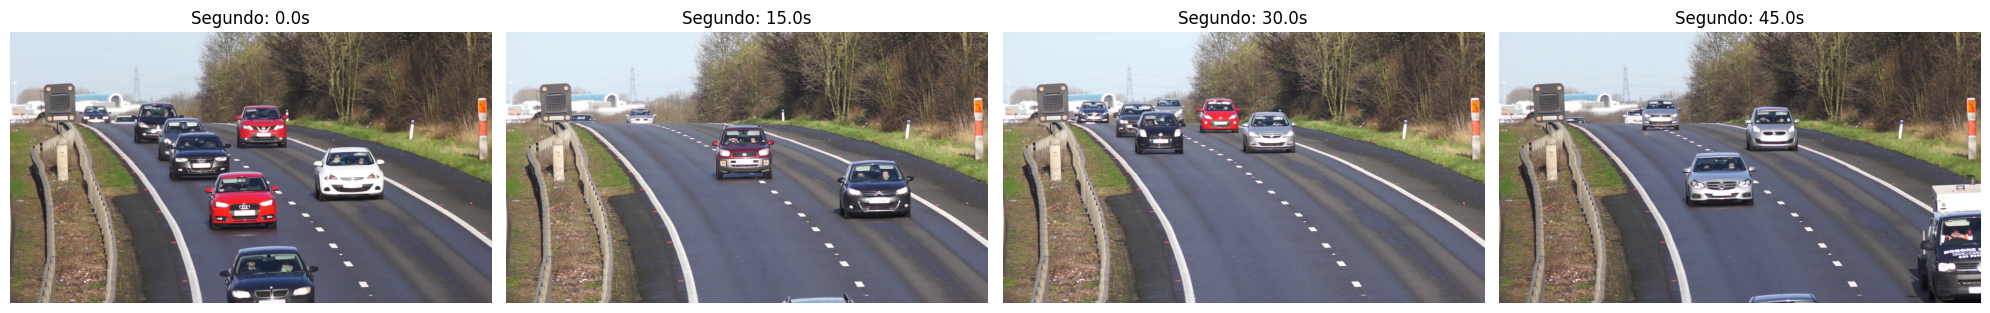

In [ ]:
import matplotlib.pyplot as plt

# Verificar que existan fotogramas en gemini_frames
if 'gemini_frames' in globals() and gemini_frames:
    num_frames = len(gemini_frames)
    fig, axes = plt.subplots(1, num_frames, figsize=(5 * num_frames, 5))

    # Asegurar que axes sea un array incluso si solo hay 1 frame
    if num_frames == 1:
        axes = [axes]

    for idx, (elapsed, pil_image) in enumerate(gemini_frames):
        axes[idx].imshow(pil_image)
        axes[idx].set_title(f"Segundo: {elapsed:.1f}s")
        axes[idx].axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("No se encontraron fotogramas en 'gemini_frames'.")

In [ ]:

print("=== RESUMEN DEL ANÁLISIS ===")
print(f"Duración procesada: {len(df) / fps:.1f} segundos")
print(f"Fotogramas procesados: {len(df)}")
print(f"Promedio por fotograma: "
      f"{df['vehiculos_detectados'].mean():.2f}")
print(f"Máximo por fotograma: "
      f"{df['vehiculos_detectados'].max()}")

print("\nDetecciones acumuladas por clase:")
print(df[class_columns].sum().to_string())

print("\nArchivos generados:")
for path in [VIDEO_OUT, CHART_TIME, CHART_CLASS, CSV_OUT, REPORT_OUT]:
    print(f"{os.path.basename(path)}: "
          f"{os.path.getsize(path) / (1024**2):.2f} MB")

print("\nInforme de Gemini:")
print(scene_report)

# Descargar el video final
files.download(VIDEO_OUT)


=== RESUMEN DEL ANÁLISIS ===
Duración procesada: 45.0 segundos
Fotogramas procesados: 1125
Promedio por fotograma: 6.15
Máximo por fotograma: 12

Detecciones acumuladas por clase:
Automovil      5095
Motocicleta     121
Autobus          55
Camion         1650

Archivos generados:
carretera_tiktok.mp4: 29.18 MB
detecciones_tiempo.png: 0.13 MB
vehiculos_clase.png: 0.06 MB
estadisticas.csv: 0.02 MB
analisis_gemini.txt: 0.00 MB

Informe de Gemini:
A continuación, presento el análisis técnico de las imágenes desde la perspectiva de la visión artificial y la divulgación científica.

---

### 1. Descripción general de la escena
La escena muestra una sección de una carretera de múltiples carriles con tráfico fluyendo en un solo sentido, dirigiéndose de frente hacia el punto de observación de la cámara. En el margen izquierdo de la calzada se observa un guardarraíl metálico y un poste con un dispositivo de control o señalización apagado (con la inscripción "9448A"). En el margen derecho se apre

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import shutil

PACKAGE = "/content/analisis_carretera_tiktok.zip"

# Corregido: Se remueve el bloque 'with' innecesario
shutil.make_archive(
    PACKAGE[:-4], "zip", OUTPUT_DIR
)

'/content/analisis_carretera_tiktok.zip'

In [ ]:

import shutil
from google.colab import files

PACKAGE = "/content/analisis_carretera_tiktok.zip"

shutil.make_archive(
    PACKAGE[:-4],
    "zip",
    root_dir=OUTPUT_DIR
)

files.download(PACKAGE)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>